In [25]:
import astropy as ast #for constants etc
import astropy.constants as cst #constants 
import numpy as np
import matplotlib.pyplot as plt
import scipy as sci

# Following similar procedure as to in 'Neutron stars for undergraduates'
# Richard R. Silbar; Sanjay Reddy (2004)
# https://doi.org/10.1119/1.1703544
# the ratio of Z/A = 2 

##################################################################

c = cst.c.value # speed of light 
atomic_ratio = 2 
m_N = (cst.m_n.value + cst.m_p.value)/2
gamma = 5/3
R_0 = (cst.G.value * cst.M_sun.value) / (c**2)
eps_0 = 0.013



def K_nr(eps_0):
    return (cst.hbar.value**2) / (15 *np.pi**2 * cst.m_e.value) * ((3 * np.pi * (1/atomic_ratio) / (m_N * c**2))**(5/3))

def beta_nr(eps_0):
    return (4 * np.pi * eps_0)/(cst.M_sun.value * c**2 * (K_nr(eps_0) * eps_0**(gamma - 1)**(1/gamma)))

def alpha_nr(eps_0):
    return R_0 / ((K_nr(eps_0) * eps_0**(1/gamma))**(1 - gamma))


def dH_dr(t, eqns, Gamma, Alpha, Beta, eps_0):
    Arr = [(-Alpha(eps_0) * eqns[1]** (1/Gamma) * eqns[0]) / t**2 , 
            Beta(eps_0) * t**2 * (eqns[1])**(1/Gamma)]
    return np.array(Arr)

##################################################################



# 8900km WD 1Sol mass

# A2 poster
# Non specialised audinece 



# there's enough there toa ask about if you're stood there

/tmp/ipykernel_215288/4069239081.py:20: RuntimeWarning: invalid value encountered in scalar power
  coupling = np.array([- (fns[1] ** n) * t**2, fns[0]/(t**2)])


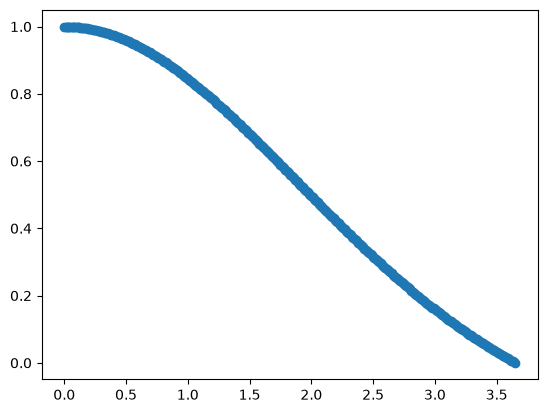

<class 'numpy.ndarray'>
365


In [35]:
import astropy as ast #for constants etc
import astropy.constants as cst #constants 
import numpy as np
import matplotlib.pyplot as plt
import scipy as sci

# Following similar procedure as to in 'Neutron stars for undergraduates'
# Richard R. Silbar; Sanjay Reddy (2004)
# https://doi.org/10.1119/1.1703544
# the ratio of Z/A = 2 

## Runga-kutta explicit method 
# fns = [u(theta(xi)), theta(xi)]

# Note: AI (Claude Sonnet 5.5) on low setting was used to assist in debugging the Runga-Kutta 4(5) 

X = np.array([0., 1.]) # these are initial conditions 

def Lane_Emden(t, fns, n):
    coupling = np.array([- (fns[1] ** n) * t**2, fns[0]/(t**2)])
    return coupling

def RK4(f, initial_conditions, initial_radius, dxi, n_steps, n):
    con = np.zeros((n_steps + 1, 2))
    con[0] = initial_conditions # the initial conditions (must be an array)

    for i in range (0, n_steps):
        k_1 = f(initial_radius + i*dxi, con[i],  n )
        N_2 = con[i] + (k_1*dxi/2)
        k_2 = f((initial_radius + i*dxi+dxi/2), N_2, n )
        N_3 = con[i] + (k_2*dxi/2)
        k_3 = f( initial_radius + i*dxi+dxi/2, N_3,  n )
        N_4 = con[i] + (k_3*dxi)
        k_4 = f(initial_radius + i*dxi+dxi, N_4,  n )
        k = 1/6 * (k_1 + 2*k_2 + 2*k_3 + k_4)
        con[i+1] = (con[i] + dxi * k)
    return con 



steps = 400
infintesimal = 0.01
order_n = 1
initial_radius = 0.00000000000000001 
ns = [3/2]


plt.figure()
for k in range(len(ns)):
    solved = RK4(Lane_Emden, X, initial_radius, infintesimal, steps, n = ns[k])
    plt.scatter(initial_radius + infintesimal * np.arange(steps + 1), solved[:,1])


plt.show()

def linear_line(grad, intercept, x):
    return grad * x + intercept

def zero_finder(xs, ys, dxi): # this uses a linear interpolation 
    i = 0 
    while ys[i] > 0:
        i += 1 
    dy = ys[i-1] - ys[i-2]
    dx = xs[i-1] - xs[i-2]
    gradient = dy/dx
    intercept = ys[i-1]
    k = 0
    interp = [ys[i]]
    while interp[k] > 0:
        interp.append(linear_line(gradient, intercept, (interp[k] + dxi / 100)))
        k += 1
    print(k)
    zero_x_position = (xs[k - 1] - xs[k])/2
    return zero_x_position


positive_values = np.where(solved[:,1] > 0)
last_positive = np.array(positive_values)[0][-1]




# print(zero_finder(initial_radius + infintesimal * np.arange(steps + 1), solved[:,1], infintesimal ))



# solved = RK4(Lane_Emden, X, initial_radius, infintesimal, steps, n = order_n)


# # # print(solved)

# plt.scatter(initial_radius + infintesimal * np.arange(steps + 1), solved[:,1])
# # # plt.scatter(solved[:1],solved[1:])